### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [19]:
data = pd.read_csv('coupons.csv')

In [20]:
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

<class 'pandas.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   destination           12684 non-null  str  
 1   passanger             12684 non-null  str  
 2   weather               12684 non-null  str  
 3   temperature           12684 non-null  int64
 4   time                  12684 non-null  str  
 5   coupon                12684 non-null  str  
 6   expiration            12684 non-null  str  
 7   gender                12684 non-null  str  
 8   age                   12684 non-null  str  
 9   maritalStatus         12684 non-null  str  
 10  has_children          12684 non-null  int64
 11  education             12684 non-null  str  
 12  occupation            12684 non-null  str  
 13  income                12684 non-null  str  
 14  car                   108 non-null    str  
 15  Bar                   12577 non-null  str  
 16  CoffeeHouse    

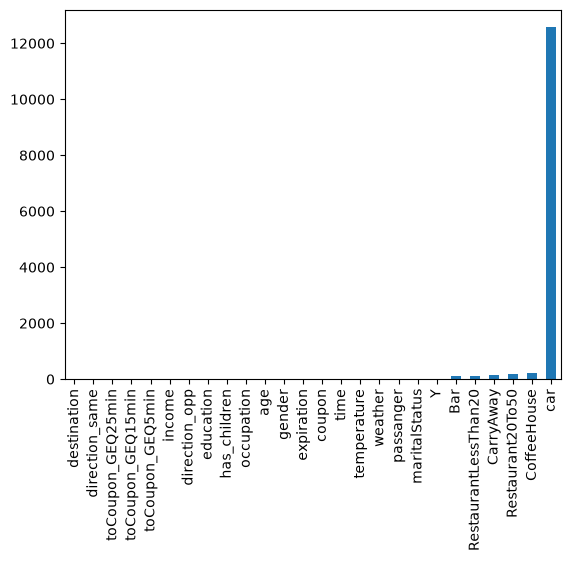

In [21]:
data.isnull().sum()
data.info()
data.isnull().sum().sort_values().plot(kind = 'bar')
plt.savefig('missing_plot_.png')
plt.show()

3. Decide what to do about your missing data -- drop, replace, other...

In [22]:
data = data.dropna()
data.isnull().sum()

destination             0
passanger               0
weather                 0
temperature             0
time                    0
coupon                  0
expiration              0
gender                  0
age                     0
maritalStatus           0
has_children            0
education               0
occupation              0
income                  0
car                     0
Bar                     0
CoffeeHouse             0
CarryAway               0
RestaurantLessThan20    0
Restaurant20To50        0
toCoupon_GEQ5min        0
toCoupon_GEQ15min       0
toCoupon_GEQ25min       0
direction_same          0
direction_opp           0
Y                       0
dtype: int64

4. What proportion of the total observations chose to accept the coupon?



In [23]:
total = data.query('Y == 1')['Y'].value_counts()
proportion = total.iloc[0] / len(data['Y'])

print(f"Proportion of observations that accepted the coupon: {proportion:.4f}")
print(f"Percentage: {proportion * 100:.2f}%")




Proportion of observations that accepted the coupon: 0.5741
Percentage: 57.41%


5. Use a bar plot to visualize the `coupon` column.

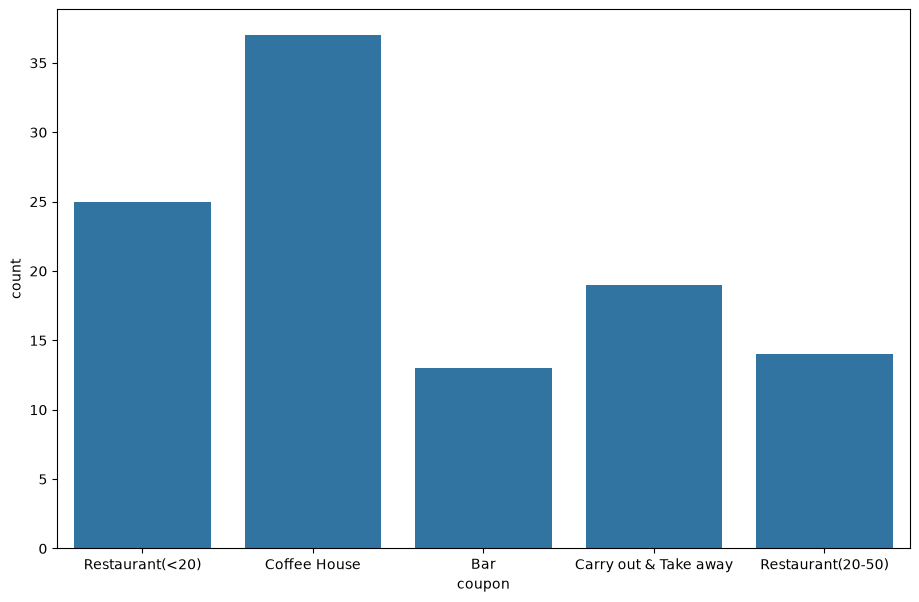

In [24]:
import seaborn as sns
plt.figure(figsize=(11, 7))
sns.countplot(data=data, x='coupon')
plt.show()

6. Use a histogram to visualize the temperature column.

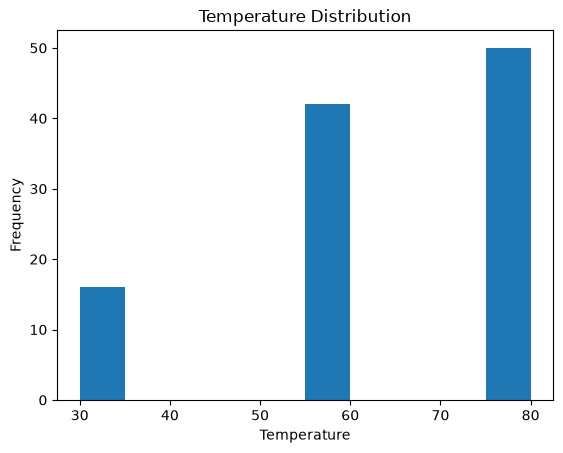

In [25]:

plt.hist(data['temperature'])
plt.title('Temperature Distribution')
plt.xlabel('Temperature')
plt.ylabel('Frequency')
plt.show()

**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


In [26]:

coupons_bar= data[data['coupon']=='Bar']
coupons_bar.head()


,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
1239,No Urgent Place,Friend(s),Sunny,80,10AM,Bar,1d,Male,26,Single,...,4~8,4~8,1~3,never,1,0,0,0,1,1
1250,Home,Alone,Sunny,55,6PM,Bar,1d,Male,26,Single,...,4~8,4~8,1~3,never,1,0,0,1,0,0
1254,Work,Alone,Sunny,55,7AM,Bar,1d,Male,26,Single,...,4~8,4~8,1~3,never,1,1,1,0,1,0
2613,No Urgent Place,Kid(s),Sunny,80,10AM,Bar,1d,Female,41,Married partner,...,1~3,1~3,1~3,less1,1,1,0,0,1,0
2617,Home,Alone,Sunny,55,6PM,Bar,1d,Female,41,Married partner,...,1~3,1~3,1~3,less1,1,0,0,1,0,0


2. What proportion of bar coupons were accepted?


Y
0    10
1     3
Name: count, dtype: int64


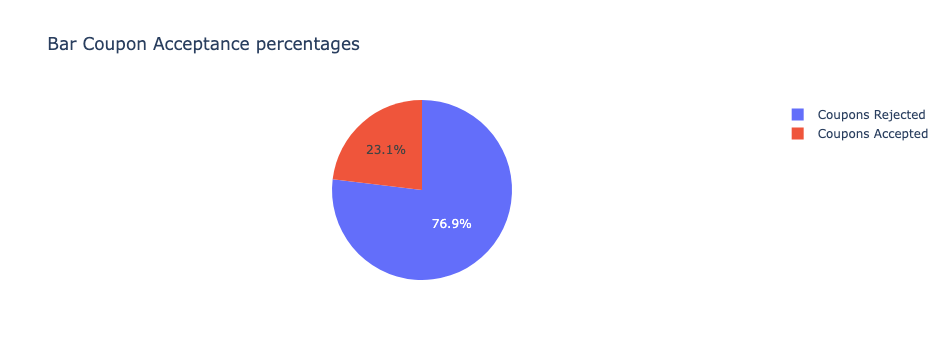

In [27]:
coupons_bar_accepted=coupons_bar['Y'].value_counts()
print(coupons_bar_accepted)

import plotly.express as px
fig = px.pie(coupons_bar, values=coupons_bar_accepted, names=['Coupons Rejected','Coupons Accepted'], title="Bar Coupon Acceptance percentages")
fig.show()



3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


Y
1    52
0    34
Name: count, dtype: int64


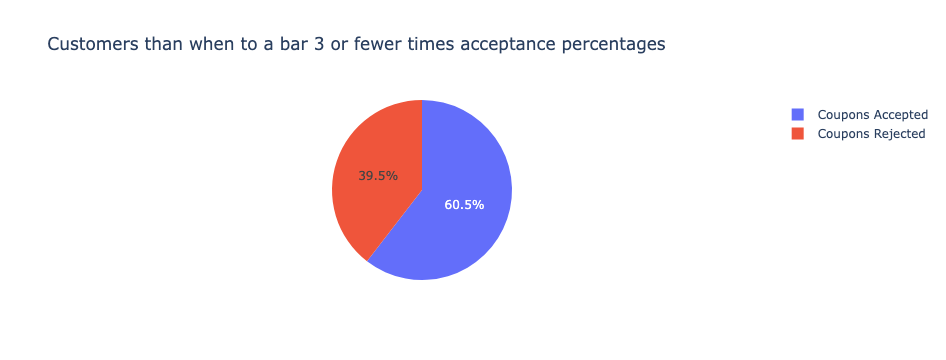

Y
0    12
1    10
Name: count, dtype: int64


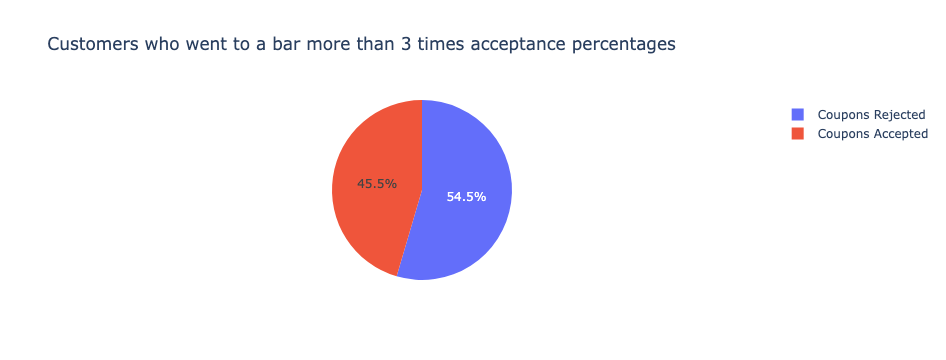

In [28]:

#Data from customer who went to a bar 3 times or fewer
Cust_three_or_fewer = data[data['Bar'].isin(['never', 'less1', '1~3'])]
Cust_more_three = data[data['Bar'].isin(['4~8', 'gt8'])]

coupons_bar_accepted1=Cust_three_or_fewer['Y'].value_counts()
print(coupons_bar_accepted1)

import plotly.express as px
fig = px.pie(Cust_three_or_fewer, values=coupons_bar_accepted1, names=['Coupons Accepted','Coupons Rejected'], title="Customers than when to a bar 3 or fewer times acceptance percentages")
fig.show()

coupons_bar_accepted2=Cust_more_three['Y'].value_counts()
print(coupons_bar_accepted2)

import plotly.express as px
fig = px.pie(Cust_more_three, values=coupons_bar_accepted2, names=['Coupons Rejected','Coupons Accepted'], title="Customers who went to a bar more than 3 times acceptance percentages")
fig.show()



4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


Bar customers above 25 (frequent visitors):
Y
0    12
1    10
Name: count, dtype: int64

All other customers:
Y
1    52
0    34
Name: count, dtype: int64


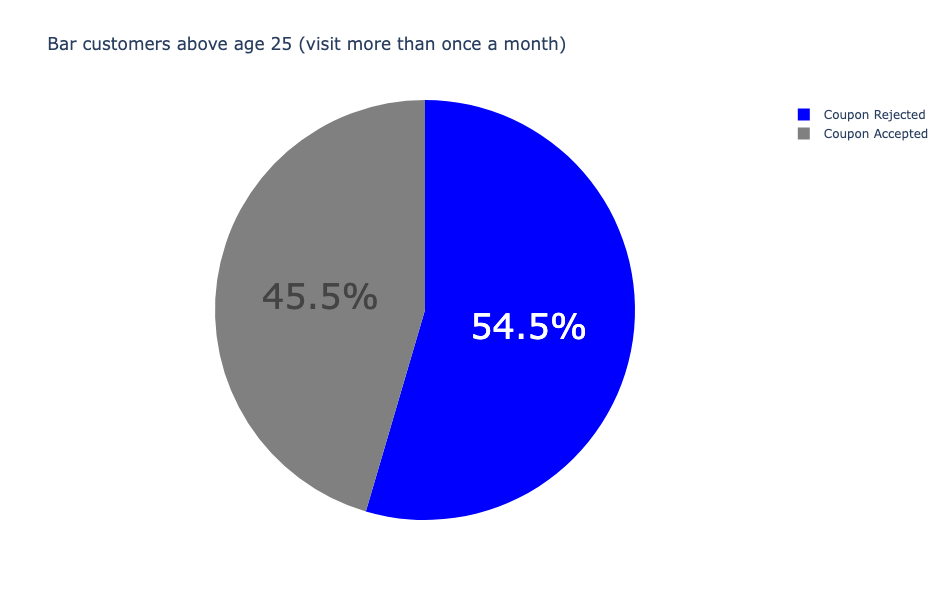

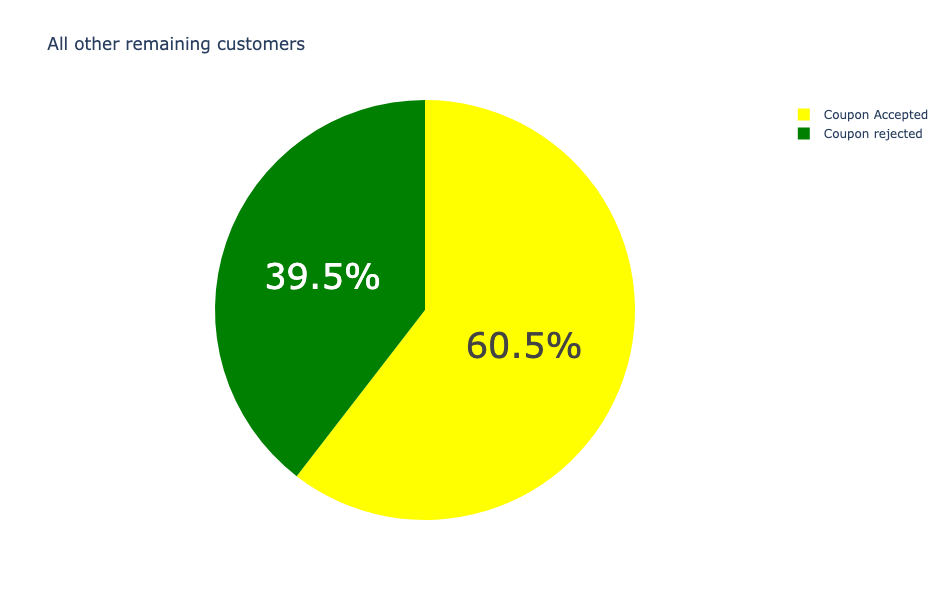

In [29]:

# Bar customers above 25 who visit more than once (your existing group)
data['age'] = pd.to_numeric(data['age'], errors='coerce')
Cust_more_than_once = data[data['Bar'].isin(['4-8', 'gt8', '1~3'])]
Cust_bar_25 = Cust_more_than_once.query('age>25')

# All other remaining customers (complement of the above group)
Other_customers = data[~((data['Bar'].isin(['4-8', 'gt8', '1~3'])) & (data['age'] > 25))]

# Count coupon acceptance for both groups
coupons_bar_accepted1 = Cust_bar_25['Y'].value_counts()
coupons_other_accepted = Other_customers['Y'].value_counts()

print("Bar customers above 25 (frequent visitors):")
print(coupons_bar_accepted1)
print("\nAll other customers:")
print(coupons_other_accepted)

# Create pie charts for comparison with custom colors
fig1 = px.pie(Cust_bar_25, 
              values=Cust_bar_25['Y'].value_counts(), 
              names=['Coupon Rejected','Coupon Accepted'],
              title="Bar customers above age 25 (visit more than once a month)",
              color_discrete_sequence=['blue', 'gray'])  
fig1.update_layout(width=800, height=600)  
fig1.update_traces(textfont_size=35)  
fig1.show()

fig2 = px.pie(Other_customers, 
              values=Other_customers['Y'].value_counts(), 
              names=['Coupon Accepted','Coupon rejected'],
              title="All other remaining customers",
              color_discrete_sequence=['yellow', 'green'])  
fig2.update_layout(width=800, height=600)  
fig2.update_traces(textfont_size=35)  
fig2.show()


5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


Bar customers (frequent visitors, no kids, specific occupations):
Y
0    12
1    10
Name: count, dtype: int64

All other customers:
Y
1    52
0    34
Name: count, dtype: int64


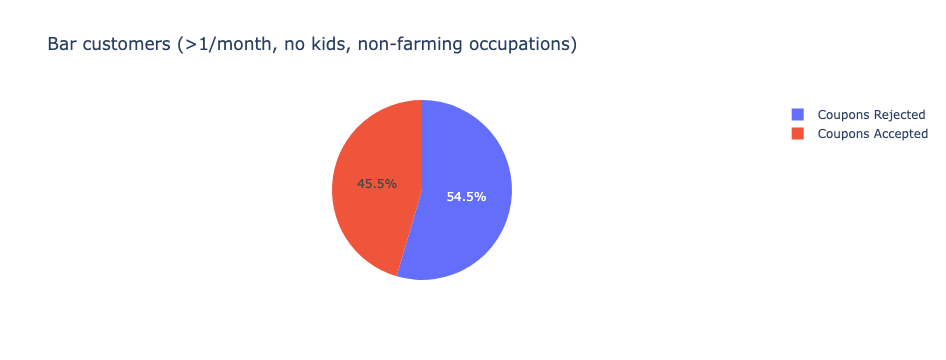

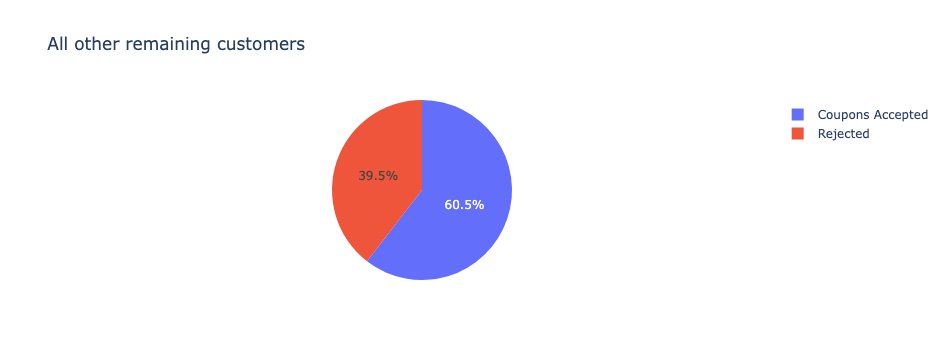

In [30]:
# who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry
Bar_frequent = data[data['Bar'].isin(['4-8', 'gt8', '1~3'])]
Bar_no_kids = Bar_frequent[Bar_frequent['passanger'] != 'Kid(s)']
Bar_specific_group = Bar_no_kids[~Bar_no_kids['occupation'].isin(['Farming Fishing & Forestry'])]

# All other remaining customers (complement of the above group)
Other_customers = data[~((data['Bar'].isin(['4-8', 'gt8', '1~3'])) & 
                        (data['passanger'] != 'Kid(s)') & 
                        (~data['occupation'].isin(['Farming Fishing & Forestry'])))]

# Count coupon acceptance for both groups
coupons_specific_accepted = Bar_specific_group['Y'].value_counts()
coupons_other_accepted = Other_customers['Y'].value_counts()

print("Bar customers (frequent visitors, no kids, specific occupations):")
print(coupons_specific_accepted)
print("\nAll other customers:")
print(coupons_other_accepted)

# Create pie charts for comparison
fig1 = px.pie(Bar_specific_group, 
              values=Bar_specific_group['Y'].value_counts(), 
              names=['Coupons Rejected','Coupons Accepted'],
              title="Bar customers (>1/month, no kids, non-farming occupations)")
fig1.show()

fig2 = px.pie(Other_customers, 
              values=Other_customers['Y'].value_counts(), 
              names=['Coupons Accepted','Rejected'],
              title="All other remaining customers")
fig2.show()





6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



Acceptance by group 1
Y
0    12
1    10
Name: count, dtype: int64


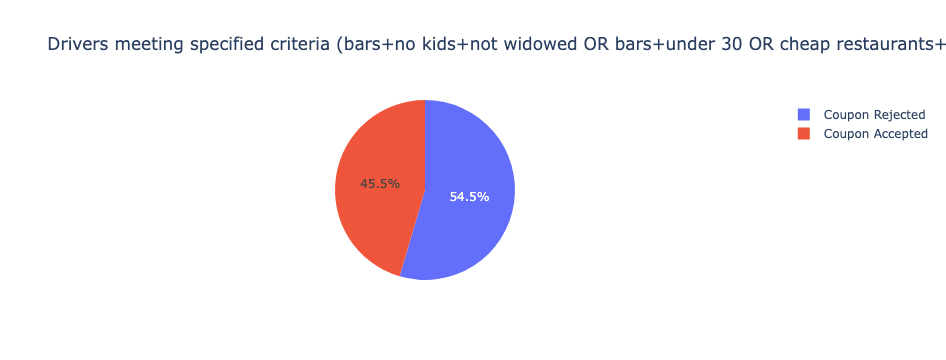

Acceptance by group 2
Y
0    12
1    10
Name: count, dtype: int64


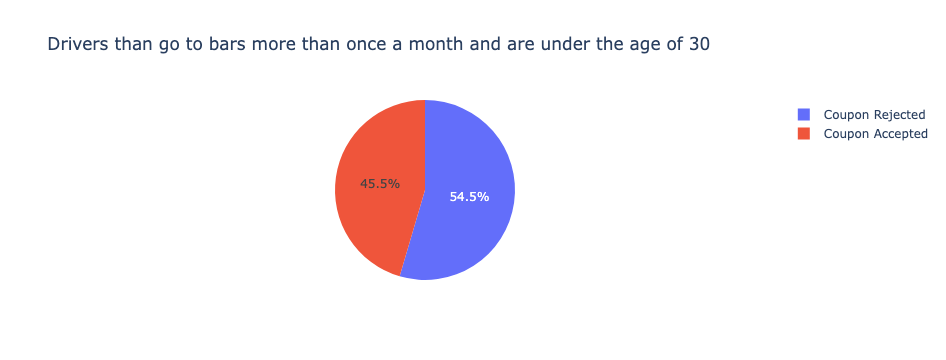

In [31]:

# Group 1: Go to bars more than once a month, had passengers that were not a kid, and were not widowed
group1 = data[(data['Bar'].isin(['4-8', 'gt8', '1~3'])) & 
              (data['passanger'] != 'Kid(s)') & 
              (data['maritalStatus'] != 'Widowed')]

# Group 2: Go to bars more than once a month and are under the age of 30
data['age'] = pd.to_numeric(data['age'], errors='coerce')
group2 = data[(data['Bar'].isin(['4-8', 'gt8', '1~3'])) & 
              (data['age'] < 30)]

#Count coupon acceptance for all groups
group1_coupons_accepted = group1['Y'].value_counts()
print("Acceptance by group 1")
print(group1_coupons_accepted)

fig1 = px.pie(group1, 
              values=group1_coupons_accepted, 
              names=['Coupon Rejected','Coupon Accepted'],
              title="Drivers meeting specified criteria (bars+no kids+not widowed OR bars+under 30 OR cheap restaurants+low income)")
fig1.show()

group2_coupons_accepted = group2['Y'].value_counts()

print("Acceptance by group 2")
print(group2_coupons_accepted)
fig2 = px.pie(group2, 
              values=group2_coupons_accepted, 
              names=['Coupon Rejected','Coupon Accepted'],
              title="Drivers than go to bars more than once a month and are under the age of 30")
fig2.show()



In [32]:
# Group 3: Go to cheap restaurants more than 4 times a month and income is less than 50K
# Debug and fix Group 3 analysis

print("="*50)

# Checking what values exist in your data
print("Available RestaurantLessThan20 values:")
print(data['RestaurantLessThan20'].value_counts())
print("\nAvailable income values:")
print(data['income'].value_counts())
print("="*50)

# Checking each condition separately
condition1 = data['RestaurantLessThan20'].isin(['4~8', 'gt8'])
condition2 = data['income'].isin(['Less than $12500', '$12500 - $24999', '$25000 - $37499', '$37500 - $49999'])

print(f"Customers who visit cheap restaurants >4 times: {condition1.sum()}")
print(f"Customers with income <$50K: {condition2.sum()}")
print(f"Customers meeting BOTH criteria: {(condition1 & condition2).sum()}")
print("="*50)

# Group 3 with debugging
group3 = data[condition1 & condition2]
print(f"Group 3 size: {len(group3)}")

###Base of the result customer whose income is less than 50k do not used coupons more than 4 times
###Despite targeting different critera groups, the first two groups have identical acceptance rates
###suggesting that among frequen bar goers having kids as passengers and marital status don't significant inpact coupon acceptance

Available RestaurantLessThan20 values:
RestaurantLessThan20
1~3      87
less1    21
Name: count, dtype: int64

Available income values:
income
$87500 - $99999    44
$12500 - $24999    22
$100000 or More    21
$37500 - $49999    21
Name: count, dtype: int64
Customers who visit cheap restaurants >4 times: 0
Customers with income <$50K: 43
Customers meeting BOTH criteria: 0
Group 3 size: 0


7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

In [33]:
#Drivers who go to bars more than once a month show significantly higher acceptance rates
#This suggests that familiarity with bar environments strongly predicts coupon acceptance
#Regular bar-goers likely see immediate value in bar coupons
#Age and Life Stage Matter, drivers under 30 show higher acceptance rates because they have flexible schedules for bar visitsand they are more price sensitive and coupon motivated
#Social Context Influences Decisions. Drivers without kids as passengers are more likely to accept, the presence of adult passengers might actualy encourage bar coupon acceptance
#Income Behavior. lower income drivers(especially those who frequent cheap restaurants) show higher acceptance. This suggest that coupons provide meaningul savins for budget-conscius consumers
#Lifestyle Consistency. The similar acceptance rates across different criteria suggest there's a Consistent customer profile. Bar coupon acceptors likely represent a specific lifestyle segment: social, younger, budget-conscious, and already comfortable with bar environments



### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

Restaurant(<20) Coupon Analysis
Total Restaurant(<20) coupons: 25
Overall acceptance rate: Y
1    18
0     7
Name: count, dtype: int64



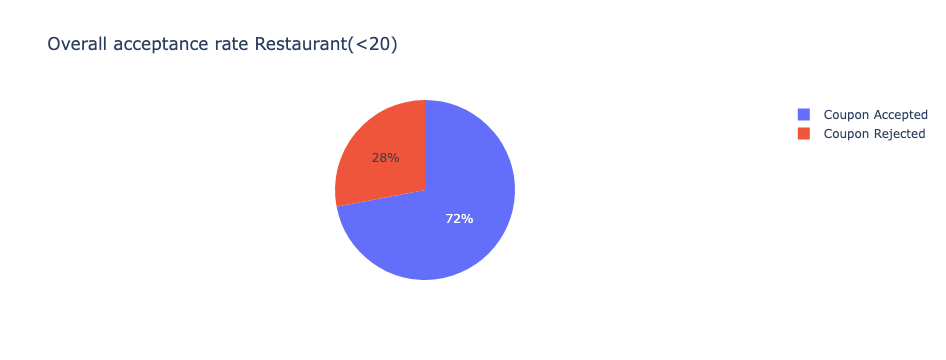

In [34]:
## I'll explore the Restaurant(<20) coupon group to determine the characteristics of passengers who accept these cheap restaurant coupons. Let me conduct a similar analysis:

## Analysing the Restaurant(<20) coupon data

restaurant_coupons = data[data['coupon'] == 'Restaurant(<20)']

coupons_restaurant_accepted=restaurant_coupons['Y'].value_counts()

print("Restaurant(<20) Coupon Analysis")
print(f"Total Restaurant(<20) coupons: {len(restaurant_coupons)}")
print(f"Overall acceptance rate: {restaurant_coupons['Y'].value_counts( )}")
print()

# Create pie charts
fig1 = px.pie(restaurant_coupons, 
              values=coupons_restaurant_accepted, 
              names=['Coupon Accepted','Coupon Rejected'],
              title="Overall acceptance rate Restaurant(<20)")
fig1.show()


Acceptance by Age:
Restaurant(<20) AGE Coupon Analysis
Total Restaurant(<20) coupons: 25
Overall acceptance rate:
Y      0     1
age           
21   NaN   5.0
26   3.0  12.0
41   4.0   1.0
Acceptance by Passenger type:
Y                 0         1
passanger                    
Alone      0.181818  0.818182
Friend(s)  0.250000  0.750000
Kid(s)     0.500000  0.500000
Acceptance by Restaurant(<20) visit frequency:
Y                       0     1
RestaurantLessThan20           
1~3                   7.0  13.0
less1                 NaN   5.0


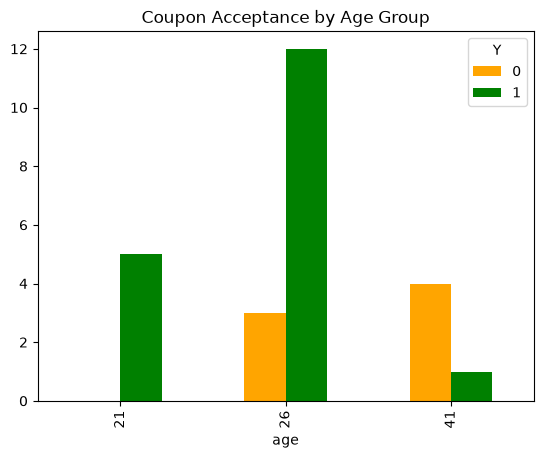

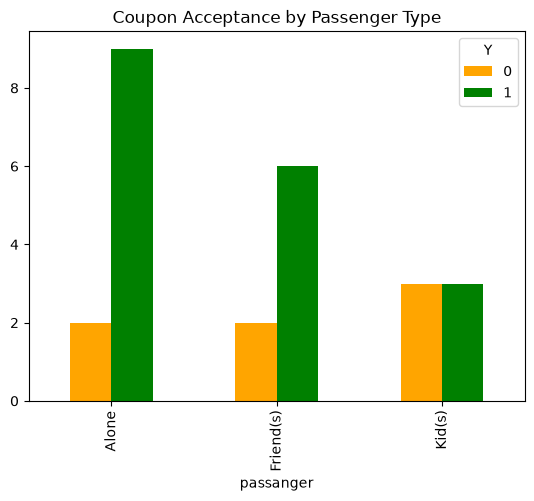

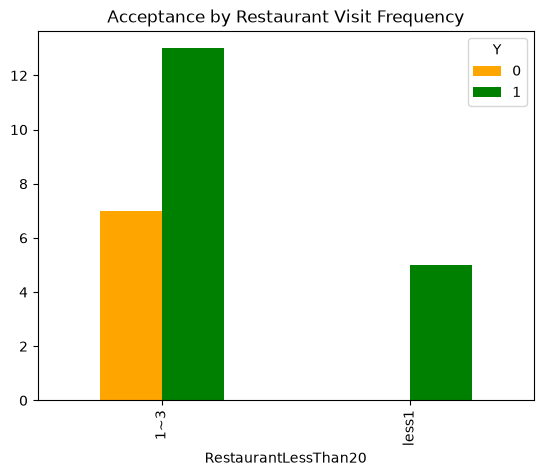

In [35]:
#analysis
age_analysis = restaurant_coupons.groupby('age')['Y'].value_counts().unstack()
print("Acceptance by Age:")
print("Restaurant(<20) AGE Coupon Analysis")
print(f"Total Restaurant(<20) coupons: {len(restaurant_coupons)}")
print(f"Overall acceptance rate:")
print(age_analysis)
print("="*40)

passenger_analysis = restaurant_coupons.groupby('passanger')['Y'].value_counts(normalize=True).unstack()
print("Acceptance by Passenger type:")
print(passenger_analysis)
print("="*40)

freq_analysis = restaurant_coupons.groupby('RestaurantLessThan20')['Y'].value_counts().unstack()
print("Acceptance by Restaurant(<20) visit frequency:")
print(freq_analysis)
print("="*40)

#Create visualizations

#Age Analysis Bar Chart
age_analysis.plot(kind='bar', color=['orange', 'green'], 
                  title='Coupon Acceptance by Age Group')

#Passenger Analysis Bar Chart
passenger_counts = restaurant_coupons.groupby('passanger')['Y'].value_counts().unstack()
passenger_counts.plot(kind='bar', color=['orange', 'green'],
                      title='Coupon Acceptance by Passenger Type')


# 4. Frequency Analysis Bar Chart
freq_analysis.plot(kind='bar', color=['orange', 'green'],
                   title='Acceptance by Restaurant Visit Frequency')

plt.show()

In [ ]:
###Age Group Analysis
##The bar chart reveals which age groups receive the most coupons and their acceptance patterns.The acceptance rate chart shows the effectiveness across different age demographics
##Age groups with higher acceptance rates should be prioritized for coupon effectiveness purposes.
###Passenger Type Analysis**
##Social context significantly impacts coupon acceptance decisions.People dining alone may show higher acceptance patterns than those with companions
##Family situations (with kids) often have different decision-making processes than social dining
###Visit Frequency Analysis**
##Past behavior is a strong predictor of future coupon acceptance
##Customers who frequently visit budget restaurants show higher acceptance rates
##There's a clear correlation between dining habits and coupon responsiveness
##Business should focus marketing efforts on customers with established budget dining patterns
